<a href="https://colab.research.google.com/github/IvanRUDN/IST2026_autumn/blob/main/Lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 4. Машины опорных векторов (SVM)



###  Подключение библиотек


In [ ]:
!pip -q install cvxopt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cvxopt import matrix, solvers
from sklearn.datasets import make_blobs, make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

solvers.options['show_progress'] = False
np.random.seed(42)
plt.rcParams['figure.figsize'] = (6, 4)


##  Квадратичное программирование


In [ ]:
P = matrix(np.diag([1.0, 0.0]), tc='d')
q = matrix(np.array([3.0, 4.0]), tc='d')
G = matrix(np.array([[-1., 0.], [0., -1.], [-1., -3.], [2., 5.], [3., 4.]]), tc='d')
h = matrix(np.array([0., 0., -15., 100., 80.]), tc='d')
sol = solvers.qp(P, q, G, h)
print('Решение:', np.array(sol['x']).ravel())
print('Минимум функции:', sol['primal objective'])


Решение: [7.13181641e-07 5.00000101e+00]
Минимум функции: 20.00000617311241


In [ ]:
P = np.diag([2., 8.])
q = np.array([-8., -16.])
x_free = np.linalg.solve(P, -q)
print('Минимум без ограничений:', x_free)

P = matrix(np.diag([2., 8.]), tc='d')
q = matrix(q, tc='d')
G_np = np.array([[1., 1.], [-1., 0.], [1., 0.], [0., -1.]])
h_np = np.array([5., 0., 3., 0.])
G = matrix(G_np, tc='d')
h = matrix(h_np, tc='d')
sol = solvers.qp(P, q, G, h)
x_star = np.array(sol['x']).ravel()
print('Решение с ограничениями:', x_star)
print('Значение функции:', -8*x_star[0]-16*x_star[1]+x_star[0]**2+4*x_star[1]**2)
for i in range(len(h_np)):
    slack = h_np[i] - G_np[i] @ x_star
    print(i+1, 'запас =', round(slack, 7), 'активно' if abs(slack)<1e-6 else 'неактивно')


Минимум без ограничений: [4. 2.]
Решение с ограничениями: [2.99999983 1.99869093]
Значение функции: -30.999992805539023
1 запас = 0.0013092 неактивно
2 запас = 2.9999998 неактивно
3 запас = 2e-07 активно
4 запас = 1.9986909 неактивно


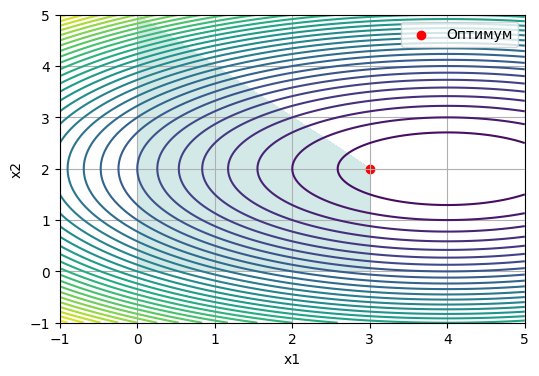

Без ограничения x1 <= 3: [3.19999978 1.79999995]


In [ ]:
x1 = np.linspace(-1, 5, 200)
x2 = np.linspace(-1, 5, 200)
xx1, xx2 = np.meshgrid(x1, x2)
f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2
ok = (xx1+xx2<=5) & (xx1>=0) & (xx1<=3) & (xx2>=0)
plt.contour(xx1, xx2, f, 30)
plt.contourf(xx1, xx2, ok, levels=[0.5, 1.5], alpha=.2)
plt.scatter(x_star[0], x_star[1], color='red', label='Оптимум')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.grid(); plt.show()

G_short = matrix(G_np[[0, 1, 3]], tc='d')
h_short = matrix(h_np[[0, 1, 3]], tc='d')
sol_short = solvers.qp(P, q, G_short, h_short)
print('Без ограничения x1 <= 3:', np.array(sol_short['x']).ravel())


###  Линейный SVM


In [ ]:
class LinearSVM:
    def __init__(self, C=1.0, transform=None):
        self.C = C
        self.transform = transform

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if self.transform is not None:
            X = self.transform(X)
        n, d = X.shape
        P = np.zeros((d+1+n, d+1+n))
        P[:d, :d] = np.eye(d)
        q = np.r_[np.zeros(d+1), np.full(n, self.C)]
        G1 = np.hstack([-y[:, None]*X, -y[:, None], -np.eye(n)])
        G2 = np.hstack([np.zeros((n, d+1)), -np.eye(n)])
        G = np.vstack([G1, G2])
        h = np.r_[-np.ones(n), np.zeros(n)]
        sol = solvers.qp(matrix(P, tc='d'), matrix(q, tc='d'),
                         matrix(G, tc='d'), matrix(h, tc='d'))
        z = np.array(sol['x']).ravel()
        self.weights_ = z[:d]
        self.bias_ = z[d]
        self.support_vectors_ = X[np.abs(y*(X@self.weights_+self.bias_)-1+z[d+1:]) < 1e-4]
        self.support_mask_ = z[d+1:] > 1e-5
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        if self.transform is not None:
            X = self.transform(X)
        return X @ self.weights_ + self.bias_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

def phi(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.c_[x1, x2, x1**2, x1*x2, x2**2]

def plot_model(model, X, y, title):
    a = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 250)
    b = np.linspace(X[:,1].min()-1, X[:,1].max()+1, 250)
    xx, yy = np.meshgrid(a, b)
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure()
    plt.contourf(xx, yy, zz, levels=20, alpha=.2, cmap='coolwarm')
    plt.contour(xx, yy, zz, levels=[-1,0,1], colors='black',
                linestyles=['--','-','--'])
    plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', edgecolors='k')
    plt.title(title); plt.show()


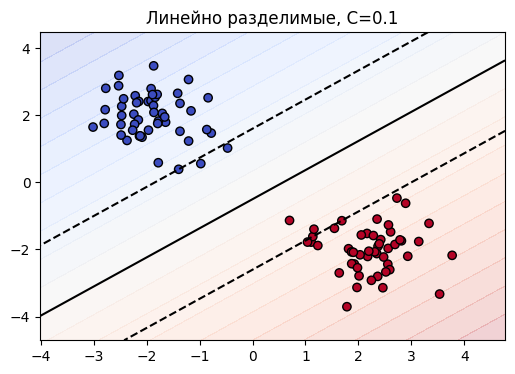

Линейно разделимые C= 0.1 опорных векторов: 4


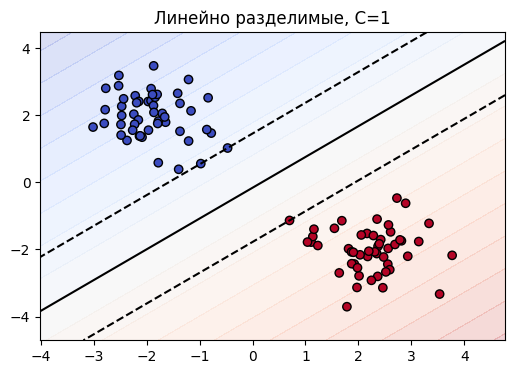

Линейно разделимые C= 1 опорных векторов: 0


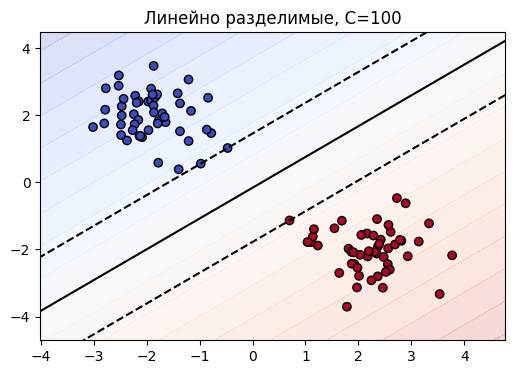

Линейно разделимые C= 100 опорных векторов: 0


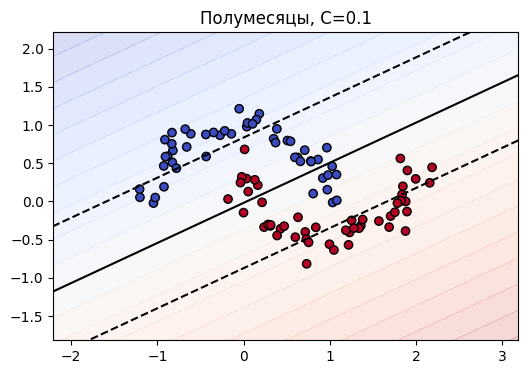

Полумесяцы C= 0.1 опорных векторов: 53


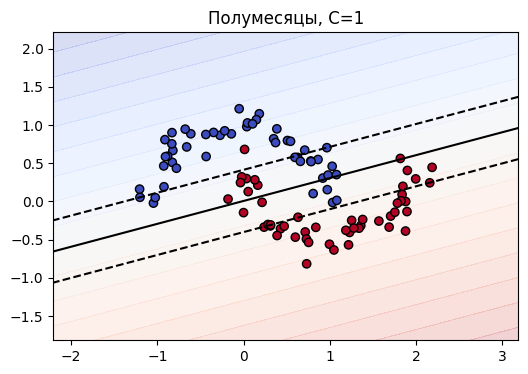

Полумесяцы C= 1 опорных векторов: 33


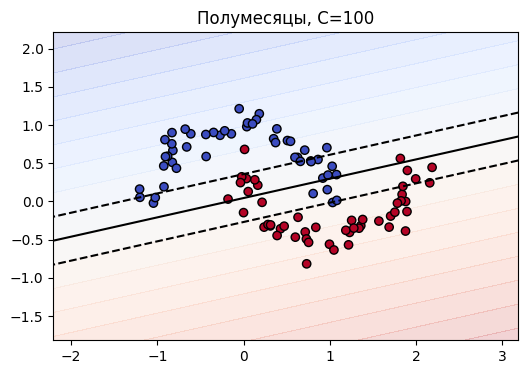

Полумесяцы C= 100 опорных векторов: 27


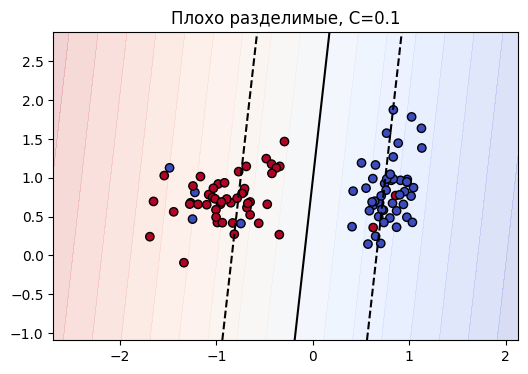

Плохо разделимые C= 0.1 опорных векторов: 40


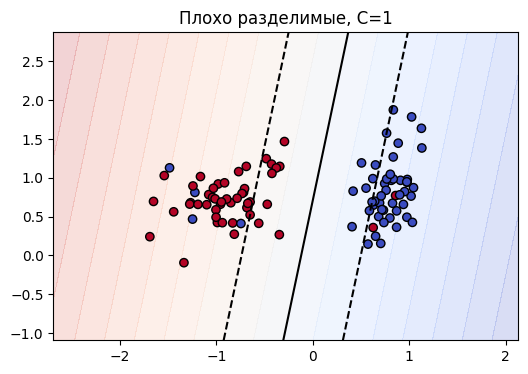

Плохо разделимые C= 1 опорных векторов: 23


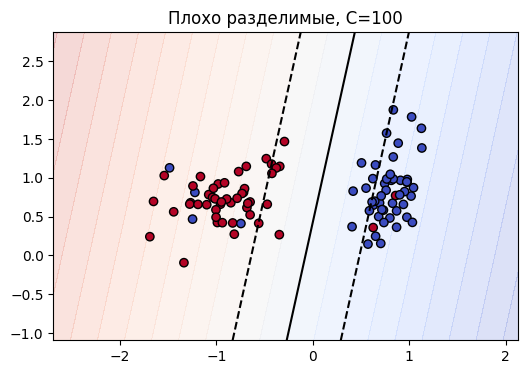

Плохо разделимые C= 100 опорных векторов: 20


In [ ]:
X1, y1 = make_blobs(n_samples=100, centers=[(-2, 2), (2, -2)], cluster_std=.7, random_state=1)
X2, y2 = make_moons(n_samples=100, noise=.12, random_state=1)
X3, y3 = make_classification(n_samples=100, n_features=2, n_redundant=0,
                             n_informative=2, n_clusters_per_class=1,
                             flip_y=.15, class_sep=.8, random_state=1)
datasets = [('Линейно разделимые', X1, 2*y1-1),
            ('Полумесяцы', X2, 2*y2-1),
            ('Плохо разделимые', X3, 2*y3-1)]
for name, X, y in datasets:
    for C in [.1, 1, 100]:
        model = LinearSVM(C=C).fit(X, y)
        plot_model(model, X, y, name + ', C=' + str(C))
        print(name, 'C=', C, 'опорных векторов:', model.support_mask_.sum())


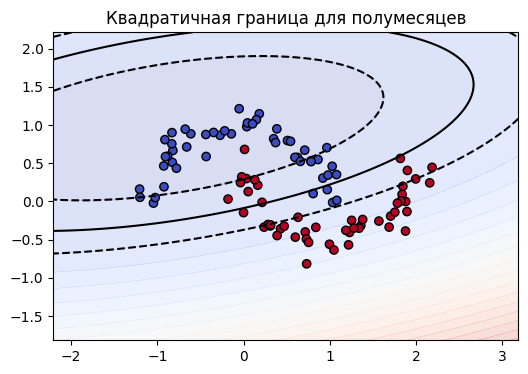

In [ ]:
model_quad = LinearSVM(C=10, transform=phi).fit(X2, 2*y2-1)
plot_model(model_quad, X2, 2*y2-1, 'Квадратичная граница для полумесяцев')


##  Двойственный SVM и ядра


In [ ]:
def linear_kernel(A, B):
    return A @ B.T

def poly_kernel(A, B, p=2):
    return (A @ B.T + 1)**p

def rbf_kernel(A, B, gamma=1.0):
    d = np.sum(A*A, axis=1)[:,None] + np.sum(B*B, axis=1)[None,:] - 2*A@B.T
    return np.exp(-gamma*np.maximum(d, 0))

class DualSVM:
    def __init__(self, C=1.0, kernel=None):
        self.C = C
        self.kernel = kernel if kernel is not None else linear_kernel

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=float)
        n = len(y)
        K = self.kernel(self.X_, self.X_)
        P = (self.y_[:,None]*self.y_[None,:])*K
        P = (P+P.T)/2 + np.eye(n)*1e-8
        G = np.vstack([-np.eye(n), np.eye(n)])
        h = np.r_[np.zeros(n), np.full(n, self.C)]
        sol = solvers.qp(matrix(P, tc='d'), matrix(-np.ones(n), tc='d'),
                         matrix(G, tc='d'), matrix(h, tc='d'),
                         matrix(self.y_[None,:], tc='d'), matrix(np.zeros(1), tc='d'))
        self.alpha_ = np.array(sol['x']).ravel()
        self.support_mask_ = self.alpha_ > 1e-5
        self.support_vectors_ = self.X_[self.support_mask_]
        sv = self.support_mask_
        self.bias_ = np.mean(self.y_[sv] - (self.alpha_*self.y_) @ K[:, sv])
        return self

    def decision_function(self, X):
        return self.kernel(np.asarray(X, dtype=float), self.X_) @ (self.alpha_*self.y_) + self.bias_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)


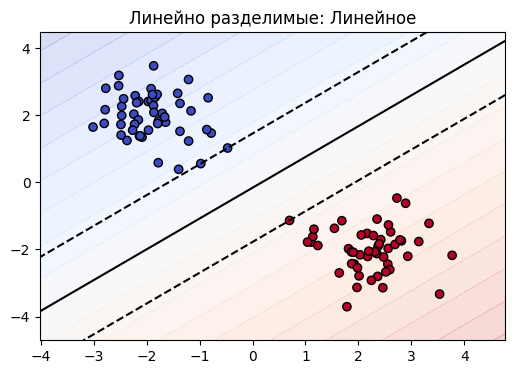

Линейное accuracy: 1.0 опорных векторов: 3


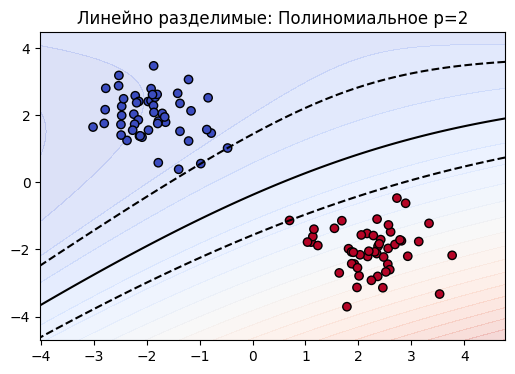

Полиномиальное p=2 accuracy: 1.0 опорных векторов: 3


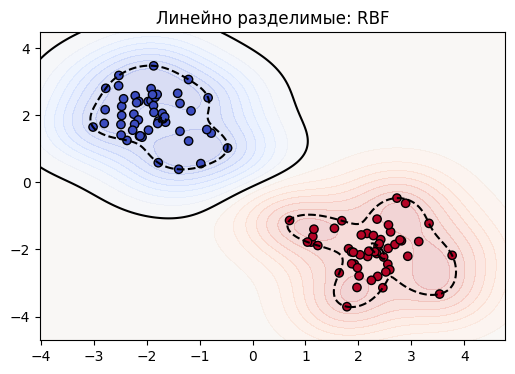

RBF accuracy: 1.0 опорных векторов: 31


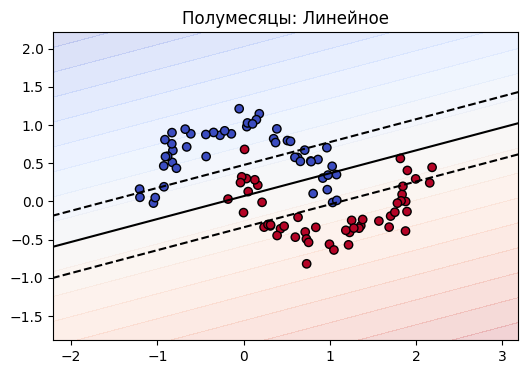

Линейное accuracy: 0.85 опорных векторов: 37


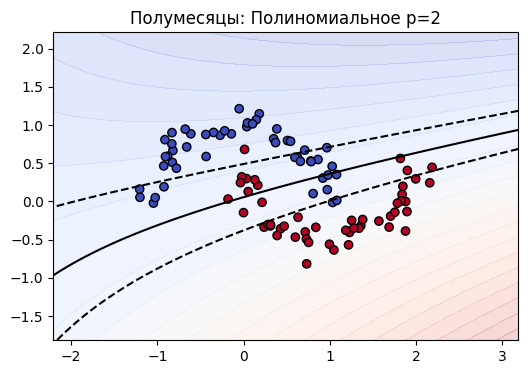

Полиномиальное p=2 accuracy: 0.85 опорных векторов: 34


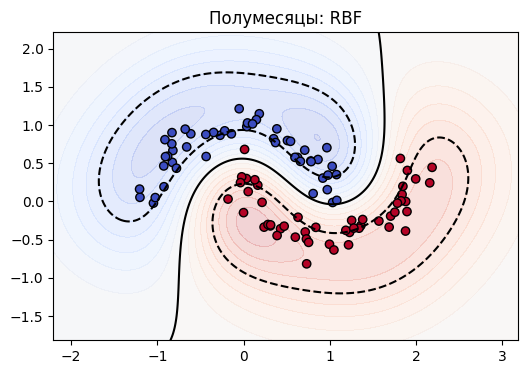

RBF accuracy: 0.99 опорных векторов: 30


In [ ]:
for name, X, y in datasets[:2]:
    for kernel_name, kernel in [('Линейное', linear_kernel),
                                ('Полиномиальное p=2', lambda A,B: poly_kernel(A,B,2)),
                                ('RBF', lambda A,B: rbf_kernel(A,B,1.0))]:
        model = DualSVM(C=1, kernel=kernel).fit(X, y)
        plot_model(model, X, y, name + ': ' + kernel_name)
        print(kernel_name, 'accuracy:', accuracy_score(y, model.predict(X)),
              'опорных векторов:', model.support_mask_.sum())


In [ ]:
for p in [2, 3, 4]:
    for C in [.1, 1, 10]:
        model = DualSVM(C=C, kernel=lambda A,B,p=p: poly_kernel(A,B,p)).fit(X2, 2*y2-1)
        print('Полином: p =', p, 'C =', C,
              'accuracy =', round(accuracy_score(2*y2-1, model.predict(X2)), 3),
              'SV =', model.support_mask_.sum())

for gamma in [.1, 1, 10]:
    for C in [.1, 1, 10]:
        model = DualSVM(C=C, kernel=lambda A,B,g=gamma: rbf_kernel(A,B,g)).fit(X2, 2*y2-1)
        print('RBF: gamma =', gamma, 'C =', C,
              'accuracy =', round(accuracy_score(2*y2-1, model.predict(X2)), 3),
              'SV =', model.support_mask_.sum())


Полином: p = 2 C = 0.1 accuracy = 0.85 SV = 47
Полином: p = 2 C = 1 accuracy = 0.85 SV = 34
Полином: p = 2 C = 10 accuracy = 0.87 SV = 32
Полином: p = 3 C = 0.1 accuracy = 0.95 SV = 38
Полином: p = 3 C = 1 accuracy = 0.99 SV = 18
Полином: p = 3 C = 10 accuracy = 1.0 SV = 10
Полином: p = 4 C = 0.1 accuracy = 0.98 SV = 28
Полином: p = 4 C = 1 accuracy = 1.0 SV = 12
Полином: p = 4 C = 10 accuracy = 1.0 SV = 8
RBF: gamma = 0.1 C = 0.1 accuracy = 0.78 SV = 94
RBF: gamma = 0.1 C = 1 accuracy = 0.85 SV = 51
RBF: gamma = 0.1 C = 10 accuracy = 0.9 SV = 35
RBF: gamma = 1 C = 0.1 accuracy = 0.9 SV = 78
RBF: gamma = 1 C = 1 accuracy = 0.99 SV = 30
RBF: gamma = 1 C = 10 accuracy = 0.99 SV = 13
RBF: gamma = 10 C = 0.1 accuracy = 0.99 SV = 100
RBF: gamma = 10 C = 1 accuracy = 1.0 SV = 47
RBF: gamma = 10 C = 10 accuracy = 1.0 SV = 44


##  Реальные данные: болезни сердца


In [ ]:
columns = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach',
           'exang','oldpeak','slope','ca','thal','num']
try:
    df = pd.read_csv('/content/Кек4.2.csv', names=columns, na_values='?')
except:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df = pd.read_csv(file_name, names=columns, na_values='?')

print('Размер:', df.shape)
display(df.head())
print(df.isna().sum())
print(df['num'].value_counts())


Saving heart.csv to heart.csv
Размер: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [ ]:
df = df.dropna().copy()
y = (df['num'] > 0).astype(int)*2-1
X = df.drop(columns='num')
X = pd.get_dummies(X, columns=['cp','restecg','slope','thal'], dtype=float)
print('После подготовки:', X.shape)
display(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


После подготовки: (297, 22)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0


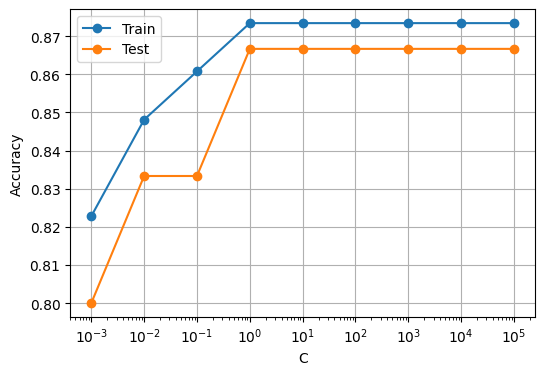

Лучшее C: 1.0
Train: 0.8734177215189873 Test: 0.8666666666666667
Доля опорных векторов: 0.3037974683544304


In [ ]:
Cs = np.logspace(-3, 5, 9)
train_scores, test_scores = [], []
linear_models = []
for C in Cs:
    model = LinearSVM(C=C).fit(X_train_s, y_train)
    linear_models.append(model)
    train_scores.append(accuracy_score(y_train, model.predict(X_train_s)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test_s)))
plt.semilogx(Cs, train_scores, marker='o', label='Train')
plt.semilogx(Cs, test_scores, marker='o', label='Test')
plt.xlabel('C'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(); plt.show()
best_i = int(np.argmax(test_scores))
best_linear = linear_models[best_i]
print('Лучшее C:', Cs[best_i])
print('Train:', train_scores[best_i], 'Test:', test_scores[best_i])
print('Доля опорных векторов:', best_linear.support_mask_.mean())


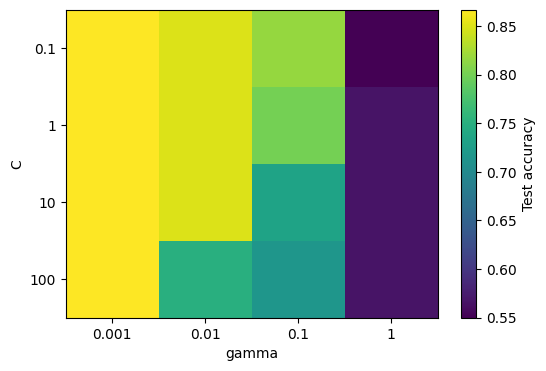

Лучшие параметры RBF: 0.1 0.001
Accuracy RBF: 0.8666666666666667


In [ ]:
Cs_rbf = [0.1, 1, 10, 100]
gammas = [.001, .01, .1, 1]
scores = np.zeros((len(Cs_rbf), len(gammas)))
rbf_models = {}
for i, C in enumerate(Cs_rbf):
    for j, gamma in enumerate(gammas):
        model = DualSVM(C=C, kernel=lambda A,B,g=gamma: rbf_kernel(A,B,g)).fit(X_train_s, y_train)
        scores[i,j] = accuracy_score(y_test, model.predict(X_test_s))
        rbf_models[(C,gamma)] = model
plt.imshow(scores, aspect='auto', cmap='viridis')
plt.xticks(range(len(gammas)), gammas); plt.yticks(range(len(Cs_rbf)), Cs_rbf)
plt.xlabel('gamma'); plt.ylabel('C'); plt.colorbar(label='Test accuracy'); plt.show()
best_pair = np.unravel_index(np.argmax(scores), scores.shape)
best_C, best_gamma = Cs_rbf[best_pair[0]], gammas[best_pair[1]]
best_rbf = rbf_models[(best_C,best_gamma)]
print('Лучшие параметры RBF:', best_C, best_gamma)
print('Accuracy RBF:', scores[best_pair])


In [ ]:
svc_linear = SVC(C=Cs[best_i], kernel='linear').fit(X_train_s, y_train)
svc_rbf = SVC(C=best_C, gamma=best_gamma, kernel='rbf').fit(X_train_s, y_train)
print('Свой LinearSVM:', accuracy_score(y_test, best_linear.predict(X_test_s)))
print('Sklearn linear:', accuracy_score(y_test, svc_linear.predict(X_test_s)))
print('Свой RBF:', accuracy_score(y_test, best_rbf.predict(X_test_s)))
print('Sklearn RBF:', accuracy_score(y_test, svc_rbf.predict(X_test_s)))


Свой LinearSVM: 0.8666666666666667
Sklearn linear: 0.8666666666666667
Свой RBF: 0.8666666666666667
Sklearn RBF: 0.5333333333333333


In [ ]:
no_scaler = LinearSVM(C=Cs[best_i]).fit(X_train.to_numpy(), y_train)
print('Без масштабирования, train:',
      accuracy_score(y_train, no_scaler.predict(X_train.to_numpy())))
print('Без масштабирования, test:',
      accuracy_score(y_test, no_scaler.predict(X_test.to_numpy())))

importance = pd.Series(np.abs(best_linear.weights_), index=X.columns).sort_values(ascending=False)
display(importance.to_frame('Важность |w|'))

print('Число опорных векторов:', best_linear.support_mask_.sum())
print('Размер train:', len(y_train))
print('Доля:', round(best_linear.support_mask_.mean()*100, 2), '%')


Без масштабирования, train: 0.8734177215189873
Без масштабирования, test: 0.8666666666666667


,Важность |w|
ca,7.931879e-01
oldpeak,4.986976e-01
sex,4.258311e-01
thal_7.0,3.607120e-01
cp_4.0,3.365357e-01
trestbps,3.031778e-01
cp_3.0,2.874213e-01
slope_1.0,2.848194e-01
cp_1.0,2.568207e-01
thal_3.0,2.527371e-01


Число опорных векторов: 72
Размер train: 237
Доля: 30.38 %
